<h1 align="center"><b>Imputation & Missing Values</b></h1>

## **Task 3.1 – Load and Inspect the  Dataset**

### Import Libraries & Load Utility Functions

In [177]:
import sys
import importlib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer

sys.path.append("../src")

import imputation_utils
importlib.reload(imputation_utils)
from imputation_utils import (
    read_file, inspect_data, assess_missing_invalid, check_duplicates, compare_missing_values, impute_missing, validate_cleaning)

### 1.Loading and  Data Inspection

- Checked dataset shape and columns.
- Reviewed sample rows and data types.
- Checked missing values and duplicates.
- Explored summary statistics.

In [178]:
df = read_file("../data/pew_religion.csv")
inspect_data(df)

1. Dataset Shape:
(36918, 17)

2. Column Names:
['P_SUID', 'WEIGHT', 'YEAR_FROM_CODATE', 'BIRTHDECADE', 'GENDER', 'EDUCREC', 'INC_SDT1', 'RACECMB', 'MARITAL', 'RELTRAD', 'RELIMP', 'ATTNDPERRLS', 'PRAY', 'HAPPY', 'PARTY', 'IDEO', 'AGE_ESTIMATED']

3. First 10 Rows:


c:\Users\admin\Desktop\Ai-Fall\PROG8245-MLP\Week 6\cleaning-imputation-outliers\notebooks\../src\imputation_utils.py:7: DtypeWarning: Columns (16: AGE_ESTIMATED) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


,P_SUID,WEIGHT,YEAR_FROM_CODATE,BIRTHDECADE,GENDER,EDUCREC,INC_SDT1,RACECMB,MARITAL,RELTRAD,RELIMP,ATTNDPERRLS,PRAY,HAPPY,PARTY,IDEO,AGE_ESTIMATED
0,10000040.0,4399.707781,2023.0,1990s,A woman,Some college/associate's degree,"$30,000 to less than $40,000",White,Living with a partner,Evangelical Protestant Tradition,Very important,Once a week,Several times a day,Very happy,Republican,Very conservative,28
1,10000060.0,6693.424549,2023.0,1970s,A woman,Master's degree or higher,"$125,000 to less than $150,000",White,Married,Religiously Unaffiliated,Not at all important,Never,Never,Very happy,Democrat,Very liberal,48
2,10000140.0,3080.916226,2024.0,1980s,A woman,College graduate,"$125,000 to less than $150,000",White,Married,Catholic,Very important,Once or twice a month,Once a day,Pretty happy,Independent,Moderate,39
3,10000150.0,5470.685158,2023.0,1960s,A woman,High school or less,DON'T KNOW/REFUSED,White,Married,Religiously Unaffiliated,Not at all important,Never,Never,Not too happy,Republican,Moderate,58
4,10000160.0,2474.921511,2023.0,1970s,A woman,College graduate,"$75,000 to less than $100,000",Black or African-American,Divorced,Historically Black Protestant Tradition,Somewhat important,Seldom,Seldom,Not too happy,Democrat,Liberal,48
5,10000200.0,5220.197875,2024.0,1950s,A woman,Some college/associate's degree,"$30,000 to less than $40,000",Black or African-American,Married,Historically Black Protestant Tradition,Very important,More than once a week,Several times a day,Pretty happy,Democrat,Moderate,69
6,10000240.0,6276.829011,2023.0,1960s,A man,Some college/associate's degree,"$50,000 to less than $75,000",White,Divorced,Evangelical Protestant Tradition,Very important,A few times a year,Seldom,Pretty happy,Independent,Conservative,58
7,10000250.0,7408.343658,2024.0,1980s,A man,College graduate,"$100,000 to less than $125,000",White,Never been married,Religiously Unaffiliated,Not too important,Once or twice a month,Seldom,Not too happy,Independent,Very conservative,39
8,10000280.0,3800.264847,2024.0,1960s,A woman,College graduate,DON'T KNOW/REFUSED,White,Married,Catholic,Somewhat important,Seldom,A few times a week,Very happy,Republican,Moderate,59
9,10000420.0,3901.603222,2023.0,1970s,A woman,College graduate,"$75,000 to less than $100,000",White,Married,Catholic,Not too important,A few times a year,Once a week,Pretty happy,Democrat,Liberal,48



4. Data Types:
P_SUID              float64
WEIGHT              float64
YEAR_FROM_CODATE    float64
BIRTHDECADE             str
GENDER                  str
EDUCREC                 str
INC_SDT1                str
RACECMB                 str
MARITAL                 str
RELTRAD                 str
RELIMP                  str
ATTNDPERRLS             str
PRAY                    str
HAPPY                   str
PARTY                   str
IDEO                    str
AGE_ESTIMATED        object
dtype: object

5. Missing Values:
P_SUID                 1
WEIGHT               370
YEAR_FROM_CODATE       1
BIRTHDECADE            1
GENDER               370
EDUCREC              370
INC_SDT1               1
RACECMB                1
MARITAL                1
RELTRAD                1
RELIMP                 1
ATTNDPERRLS            1
PRAY                   1
HAPPY                370
PARTY                  1
IDEO                   1
AGE_ESTIMATED       6748
dtype: int64

6. Missing Value Percentages:
P_SUI

,P_SUID,WEIGHT,YEAR_FROM_CODATE,BIRTHDECADE,GENDER,EDUCREC,INC_SDT1,RACECMB,MARITAL,RELTRAD,RELIMP,ATTNDPERRLS,PRAY,HAPPY,PARTY,IDEO,AGE_ESTIMATED
count,3.691700e+04,36548.000000,36917.000000,36917,36548,36548,36917,36917,36917,36917,36917,36917,36917,36548,36917,36917,30170
unique,NaN,NaN,NaN,8,5,5,9,6,7,16,5,7,8,4,5,6,25
top,NaN,NaN,NaN,1950s,A woman,Some college/associate's degree,"$150,000 or more",White,Married,Religiously Unaffiliated,Very important,Seldom,Several times a day,Pretty happy,Democrat,Moderate,68
freq,NaN,NaN,NaN,7814,20315,11009,6733,28183,18915,10733,13749,9198,10275,21315,12128,13373,5839
mean,1.108337e+07,6974.734049,2023.136441,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,6.217321e+05,7593.243921,0.343261,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000004e+07,166.396325,2023.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,1.054501e+07,2594.530893,2023.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,1.108171e+07,4614.677544,2023.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1.162273e+07,8248.323894,2023.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



9. Random Sample Rows:


,P_SUID,WEIGHT,YEAR_FROM_CODATE,BIRTHDECADE,GENDER,EDUCREC,INC_SDT1,RACECMB,MARITAL,RELTRAD,RELIMP,ATTNDPERRLS,PRAY,HAPPY,PARTY,IDEO,AGE_ESTIMATED
15549,10917290.0,3888.115133,2023.0,1940s or earlier,A man,College graduate,"$50,000 to less than $75,000",White,Divorced,Mainline Protestant Tradition,Somewhat important,Once a week,A few times a week,Pretty happy,Independent,Moderate,NaN
10080,10595980.0,3051.012235,2023.0,1980s,A man,Some college/associate's degree,"$50,000 to less than $75,000",White,Married,Religiously Unaffiliated,Not at all important,Seldom,Never,Pretty happy,Independent,Moderate,38
22250,11305580.0,1830.810167,2023.0,1950s,A man,Master's degree or higher,"$125,000 to less than $150,000",White,Married,Religiously Unaffiliated,Not too important,Seldom,Seldom,Very happy,Republican,Moderate,68
4539,10270760.0,578.732495,2023.0,1950s,A woman,Master's degree or higher,"$100,000 to less than $125,000",DON'T KNOW/REFUSED,Married,Mainline Protestant Tradition,Not too important,A few times a year,A few times a week,Pretty happy,Independent,Moderate,68
25290,11481200.0,731.526782,2023.0,1950s,A woman,Master's degree or higher,DON'T KNOW/REFUSED,White,DON'T KNOW/REFUSED,Jewish,Not too important,Never,Seldom,Very happy,Democrat,Very liberal,68


Empty rows: 1


## **Task 3.2 – Assess Missing and Invalid Values**

## Task 2: Missing and Invalid Values

- Checked missing values and their percentages.
- Counted valid observations using `notnull()`.
- Checked `WEIGHT`, `YEAR_FROM_CODATE`, and `AGE_ESTIMATED` for invalid numeric values.
- Converted selected columns to numeric data types.

In [179]:
numeric_cols = ["WEIGHT", "YEAR_FROM_CODATE", "AGE_ESTIMATED"]

df = assess_missing_invalid(df, numeric_cols)

1. Missing Values:
P_SUID                 1
WEIGHT               370
YEAR_FROM_CODATE       1
BIRTHDECADE            1
GENDER               370
EDUCREC              370
INC_SDT1               1
RACECMB                1
MARITAL                1
RELTRAD                1
RELIMP                 1
ATTNDPERRLS            1
PRAY                   1
HAPPY                370
PARTY                  1
IDEO                   1
AGE_ESTIMATED       6748
dtype: int64

2. Missing Value Percentages:
P_SUID               0.00
WEIGHT               1.00
YEAR_FROM_CODATE     0.00
BIRTHDECADE          0.00
GENDER               1.00
EDUCREC              1.00
INC_SDT1             0.00
RACECMB              0.00
MARITAL              0.00
RELTRAD              0.00
RELIMP               0.00
ATTNDPERRLS          0.00
PRAY                 0.00
HAPPY                1.00
PARTY                0.00
IDEO                 0.00
AGE_ESTIMATED       18.28
dtype: float64

3. Valid Observations:
P_SUID              36917
WEIGH

## **Task 3.3 – Check Duplicates**
- Found 10 duplicate rows.
- Removed duplicate records.
- Final dataset: 36,908 rows and 17 columns.


In [180]:
check_duplicates(df)

df_clean = df.drop_duplicates().reset_index(drop=True)

print("Duplicates after:", df_clean.duplicated().sum())

1. Number of Duplicate Rows: 10

2. Duplicate Records:


,P_SUID,WEIGHT,YEAR_FROM_CODATE,BIRTHDECADE,GENDER,EDUCREC,INC_SDT1,RACECMB,MARITAL,RELTRAD,RELIMP,ATTNDPERRLS,PRAY,HAPPY,PARTY,IDEO,AGE_ESTIMATED
3199,10191460.0,5477.553927,2023.0,1980s,A woman,Some college/associate's degree,"$75,000 to less than $100,000",White,Married,Religiously Unaffiliated,Somewhat important,Once or twice a month,A few times a week,Pretty happy,Republican,Conservative,38.0
6405,10381060.0,7463.613554,2023.0,1950s,A woman,Some college/associate's degree,DON'T KNOW/REFUSED,Black or African-American,Married,Evangelical Protestant Tradition,Very important,More than once a week,Once a day,Pretty happy,Democrat,Moderate,68.0
9927,10586300.0,2785.696049,2023.0,1980s,A woman,College graduate,"$40,000 to less than $50,000",White,Never been married,Religiously Unaffiliated,Not too important,Never,Never,Not too happy,Independent,Very liberal,38.0
13183,10780210.0,1307.265392,2023.0,1990s,A man,Master's degree or higher,"$150,000 or more",White,Married,Religiously Unaffiliated,Not at all important,Seldom,Never,Pretty happy,Democrat,Liberal,28.0
18977,11111270.0,3055.283136,2023.0,1940s or earlier,A woman,College graduate,DON'T KNOW/REFUSED,Black or African-American,Widowed,Evangelical Protestant Tradition,Very important,A few times a year,Once a day,Pretty happy,Democrat,Liberal,NaN
23501,11378720.0,5586.344849,2023.0,1960s,A man,College graduate,DON'T KNOW/REFUSED,White,Married,Catholic,Very important,Once a week,Several times a day,Very happy,Republican,Conservative,58.0
26655,11562620.0,7336.060935,2023.0,1950s,A man,High school or less,"$75,000 to less than $100,000",White,Married,Catholic,Very important,Once a week,Several times a day,Pretty happy,Republican,Conservative,68.0
28978,11695610.0,1625.181698,2023.0,1950s,A man,College graduate,"$50,000 to less than $75,000",White,Living with a partner,Evangelical Protestant Tradition,Somewhat important,Seldom,Several times a day,Not too happy,Democrat,Moderate,68.0
33139,11939370.0,2229.816529,2024.0,1940s or earlier,A man,College graduate,"$50,000 to less than $75,000",White,Married,Religiously Unaffiliated,Not too important,Never,Seldom,Very happy,Independent,Moderate,NaN
36882,12156460.0,2669.049048,2023.0,1980s,A man,Some college/associate's degree,"$75,000 to less than $100,000",White,Married,Mainline Protestant Tradition,Very important,Once or twice a month,Once a week,Very happy,Republican,Moderate,38.0



Duplicates removed successfully.

3. Dataset Shape: (36908, 17)
Duplicates after: 0


### **Task 3.4 – Compare Missing-Value Strategies**

#### Creating a  copy of my dataframe and export to up_pew_religion.csv

In [181]:


# Copy the dataset after duplicate removal
df_copy = df_clean.copy()

# Export cleaned copy
df_copy.to_csv("../data/up_pew_religion.csv", index=False)

# Load the copy
df_miss = pd.read_csv("../data/up_pew_religion.csv")

# Verify duplicates
print("Duplicates:", df_miss.duplicated().sum())

Duplicates: 0


In [182]:
compare_missing_values(df_miss)

Rows dropped: 7930
Columns dropped: 17

Mean Imputation:
Missing values before: 7117
Missing values after: 0

Median Imputation:
Missing values before: 7117
Missing values after: 0

Mode Imputation:
Missing values before: 1120
Missing values after: 1119


(           P_SUID       WEIGHT  YEAR_FROM_CODATE BIRTHDECADE   GENDER  \
 0      10000040.0  4399.707781            2023.0       1990s  A woman   
 1      10000060.0  6693.424549            2023.0       1970s  A woman   
 2      10000140.0  3080.916226            2024.0       1980s  A woman   
 3      10000150.0  5470.685158            2023.0       1960s  A woman   
 4      10000160.0  2474.921511            2023.0       1970s  A woman   
 ...           ...          ...               ...         ...      ...   
 36902  12158680.0   802.452035            2024.0       1970s  A woman   
 36903  12158710.0  1177.542874            2023.0       1970s    A man   
 36904  12158800.0   594.922805            2023.0       1970s    A man   
 36906  12158860.0  1341.225604            2024.0       1960s  A woman   
 36907  12158940.0   743.141678            2023.0       1950s    A man   
 
                                EDUCREC                        INC_SDT1  \
 0      Some college/associate's de

## **Task 3.5 – Use Visualization to Support an Imputation Decision**


### Estimated Age Analysis

- Valid observations: 30,169
- Missing values: 6,749
- Mean age: 49.54
- Median age: 48
- Age range: 18–69

**Finding:** The mean and median are close, suggesting the age distribution may be relatively balanced. A histogram will help confirm this.

In [183]:
print("Age Statistics:")
print(df_miss["AGE_ESTIMATED"].describe())

print("\nMissing Values:")
print(df_miss["AGE_ESTIMATED"].isnull().sum())

Age Statistics:
count    30161.000000
mean        49.537681
std         15.352591
min         18.000000
25%         38.000000
50%         48.000000
75%         68.000000
max         69.000000
Name: AGE_ESTIMATED, dtype: float64

Missing Values:
6747


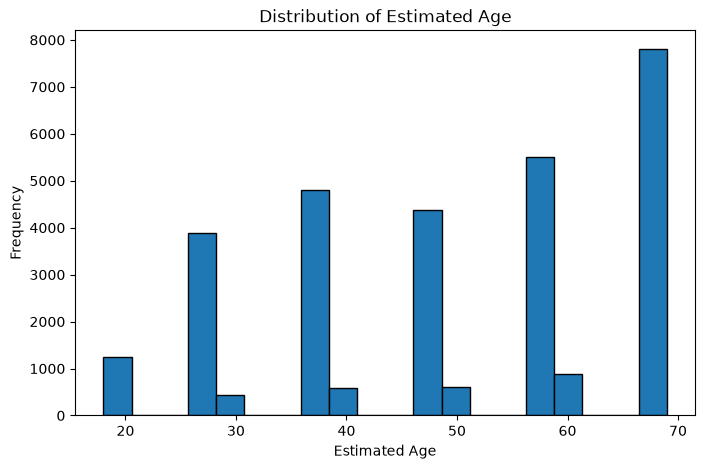

In [184]:
plt.figure(figsize=(8, 5))

plt.hist(df_miss["AGE_ESTIMATED"].dropna(), bins=20, edgecolor="black")

plt.title("Distribution of Estimated Age")
plt.xlabel("Estimated Age")
plt.ylabel("Frequency")

plt.show()

### Distribution Analysis of Estimated Age based on above graph

The histogram of **Estimated Age** shows a **negatively skewed (left-skewed) distribution**, with more observations concentrated at higher ages and fewer at lower ages.

Since the distribution is not symmetric, the **median** is a better choice than the mean for imputing missing values.

The median is less affected by extreme values and provides a more robust representation of the central tendency.

## Task 3.6 – Apply SimpleImputer
we used **SimpleImputer** with the **median strategy** to fill missing values in the Estimated Age column.

- **fit()** calculates the median.
- **transform()** fills missing values with the median.
- **fit_transform()** combines both steps.

we checked the column afterward to confirm that no missing values remained.

In [185]:
df_miss = impute_missing(df_miss, 'AGE_ESTIMATED')
print(df_miss['AGE_ESTIMATED'].isnull().sum())

0


### plotting the graph again

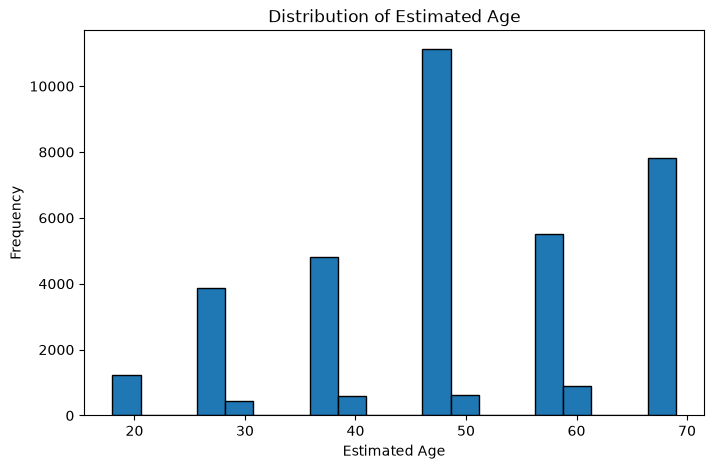

In [186]:
plt.figure(figsize=(8, 5))

plt.hist(df_miss["AGE_ESTIMATED"].dropna(), bins=20, edgecolor="black")

plt.title("Distribution of Estimated Age")
plt.xlabel("Estimated Age")
plt.ylabel("Frequency")

plt.show()

### Checking median and missing values on the current column

In [187]:
print("Median:", df_miss["AGE_ESTIMATED"].median())
print("Missing values:", df_miss["AGE_ESTIMATED"].isnull().sum())

Median: 48.0
Missing values: 0


## **Task 3.7 – Validate the Cleaned Cars Dataset**


=== Shape ===
Before: (36918, 17)
After: (36908, 17)

=== Missing Values ===
Before:
 P_SUID                 1
WEIGHT               370
YEAR_FROM_CODATE       1
BIRTHDECADE            1
GENDER               370
EDUCREC              370
INC_SDT1               1
RACECMB                1
MARITAL                1
RELTRAD                1
RELIMP                 1
ATTNDPERRLS            1
PRAY                   1
HAPPY                370
PARTY                  1
IDEO                   1
AGE_ESTIMATED       6749
dtype: int64
After:
 P_SUID                1
WEIGHT              370
YEAR_FROM_CODATE      1
BIRTHDECADE           1
GENDER              370
EDUCREC             370
INC_SDT1              1
RACECMB               1
MARITAL               1
RELTRAD               1
RELIMP                1
ATTNDPERRLS           1
PRAY                  1
HAPPY               370
PARTY                 1
IDEO                  1
AGE_ESTIMATED         0
dtype: int64

=== Duplicates ===
Before: 10
After: 0

=== De

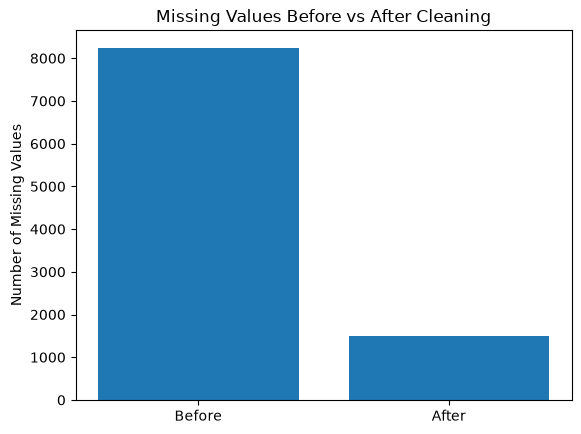

In [188]:
# Call the method
validate_cleaning(df, df_miss)

### Task 3.8 – Data Cleaning Reflection

**1. Main Data-Quality Problems**

The main problems were missing values, duplicate rows, and some invalid values.

**2. Missing Values**

We found 6,749 missing values in the `AGE_ESTIMATED` column before cleaning.

**3. Dropping Rows**

We lost 7,930 rows when we dropped rows with missing values. This means we could lose useful data that we might need later.

**4. Dropping Columns**

Some columns contain useful information, and removing them could affect the analysis.

**5. Mean Imputation**

Mean is a good choice when the data is approximately symmetric and does not have extreme values.

**6. Median Imputation**

Median is better when the data is skewed or has outliers because it is less affected by extreme values.

**7. Mode Imputation**

Mode is useful for categorical columns like `GENDER` because it fills missing values with the most common value.

**8. SimpleImputer vs fillna()**

`SimpleImputer` uses `fit()` and `transform()` to calculate and fill missing values. `fillna()` fills missing values directly.

**9. Changes in Dataset Statistics**

The changes were not very large. We removed 10 duplicate rows and filled the missing ages using the median. The mean and standard deviation changed slightly, but the median stayed at 48.

**10. Cleaning Decisions for an ML Pipeline**

We would remove duplicates and use median for skewed numerical columns and mode for categorical columns. We would also use `SimpleImputer` because it makes the cleaning process easier and more consistent.